In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from src.calibration import IsotonicCalibrator, PlattScaling
from src.data import DATASETS, RANDOM_STATE, load_splits
from src.metrics import evaluate
from src.plots import calibration_size_curve, prediction_histogram, reliability_axes, reliability_curve

sns.set_theme(style="whitegrid", context="paper")
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
FIG_DIR = ROOT / "report" 
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "LR": lambda: LogisticRegression(max_iter=1000),
    "RF": lambda: RandomForestClassifier(n_jobs=-1, random_state=RANDOM_STATE, n_estimators=101),
}

In [2]:
data = {}
for name in DATASETS:
    X_train, X_cal, X_test, y_train, y_cal, y_test = load_splits(name)
    data[name] = {"train": (X_train, y_train), "cal": (X_cal, y_cal), "test": (X_test, y_test)}

In [3]:
models = {}
for name in DATASETS:
    X, y = data[name]["train"]
    for model_name, make in MODELS.items():
        model = make().fit(X, y)
        models[name, model_name] = model
        iterations = f"  ({model.n_iter_[0]} iterations)" if model_name == "LR" else ""
        print(f"{name:10s} {model_name}: {model}{iterations}")

higgs      LR: LogisticRegression(max_iter=1000)  (17 iterations)
higgs      RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)
covertype  LR: LogisticRegression(max_iter=1000)  (93 iterations)
covertype  RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)
adult      LR: LogisticRegression(max_iter=1000)  (82 iterations)
adult      RF: RandomForestClassifier(n_estimators=101, n_jobs=-1, random_state=42)


In [4]:
outputs = {}
for (name, model_name), model in models.items():
    for split in ("cal", "test"):
        outputs[name, model_name, split] = model.predict_proba(data[name][split][0])[:,1]

np.savez_compressed(RESULTS_DIR / "uncalibrated_outputs.npz", **{f"{n}_{m}_{s}": p for (n, m, s), p in outputs.items()})

In [5]:
CALIBRATORS = {"platt": PlattScaling, "isotonic": IsotonicCalibrator}
METHODS = ["uncalibrated", *CALIBRATORS]

calibrators, probs = {}, {}
for name, model_name in models:
    y_cal = data[name]["cal"][1]
    p_cal, p_test = outputs[name, model_name, "cal"], outputs[name, model_name, "test"]
    probs[name, model_name, "uncalibrated"] = {"cal": p_cal, "test": p_test}
    for method, Calibrator in CALIBRATORS.items():
        calibrator = Calibrator().fit(p_cal, y_cal)
        calibrators[name, model_name, method] = calibrator
        probs[name, model_name, method] = {"cal": calibrator.predict_proba(p_cal), "test": calibrator.predict_proba(p_test)}

In [7]:
rows = []
for name, model_name in models:
    y_cal = data[name]["cal"][1]
    for method in METHODS:
        rows.append({"dataset": name, "model": model_name, "method": method,
                     **evaluate(y_cal, probs[name, model_name, method]["cal"])})
cal_metrics = pd.DataFrame(rows).set_index(["dataset", "model", "method"])

iso = cal_metrics.xs("isotonic", level="method")[["log_loss", "brier"]]
uncal = cal_metrics.xs("uncalibrated", level="method")[["log_loss", "brier"]]
table = cal_metrics[["log_loss", "brier"]].unstack("method")
table.loc[list(DATASETS), [(m, meth) for m in ("log_loss", "brier") for meth in METHODS]].round(4)

log_loss                         brier                 
method          uncalibrated   platt isotonic uncalibrated   platt isotonic
dataset   model                                                            
higgs     LR          0.6389  0.6372   0.6340       0.2237  0.2233   0.2221
          RF          0.5639  0.5551   0.5520       0.1910  0.1879   0.1870
covertype LR          0.5106  0.5085   0.5016       0.1685  0.1677   0.1659
          RF          0.3216  0.2989   0.2910       0.0971  0.0922   0.0907
adult     LR          0.3198  0.3356   0.3150       0.1024  0.1050   0.1013
          RF          0.3804  0.3378   0.3236       0.1025  0.1043   0.1017

In [8]:
rows = []
for name in DATASETS:
    y_train, y_test = data[name]["train"][1], data[name]["test"][1]
    rows.append({"dataset": name, "model": "constant", "method": "-",
                 **evaluate(y_test, np.full(len(y_test), y_train.mean()))})
    for model_name in MODELS:
        for method in METHODS:
            rows.append({"dataset": name, "model": model_name, "method": method,
                         **evaluate(y_test, probs[name, model_name, method]["test"])})

test_metrics = pd.DataFrame(rows)
test_metrics.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
test_metrics.set_index(["dataset", "model", "method"]).round(4)

accuracy  log_loss   brier     ece
dataset   model    method                                          
higgs     constant -               0.5285    0.6915  0.2492  0.0001
          LR       uncalibrated    0.6408    0.6372  0.2227  0.0277
                   platt           0.6420    0.6350  0.2222  0.0224
                   isotonic        0.6404    0.6462  0.2220  0.0162
          RF       uncalibrated    0.7055    0.5674  0.1928  0.0421
                   platt           0.7055    0.5614  0.1908  0.0168
                   isotonic        0.7048    0.5653  0.1910  0.0156
covertype constant -               0.5124    0.6928  0.2498  0.0000
          LR       uncalibrated    0.7580    0.5106  0.1687  0.0270
                   platt           0.7582    0.5090  0.1679  0.0117
                   isotonic        0.7588    0.5109  0.1677  0.0150
          RF       uncalibrated    0.8734    0.3259  0.0970  0.0694
                   platt           0.8726    0.2981  0.0915  0.0182
                   isotonic        0.8745    0.3138  0.0912  0.0096
adult     constant -               0.7521    0.5600  0.1864  0.0000
          LR       uncalibrated    0.8510    0.3190  0.1026  0.0084
                   platt           0.8514    0.3356  0.1053  0.0432
                   isotonic        0.8509    0.3186  0.1026  0.0056
          RF       uncalibrated    0.8515    0.3447  0.1041  0.0203
                   platt           0.8525    0.3413  0.1061  0.0350
                   isotonic        0.8534    0.3275  0.1039  0.0119

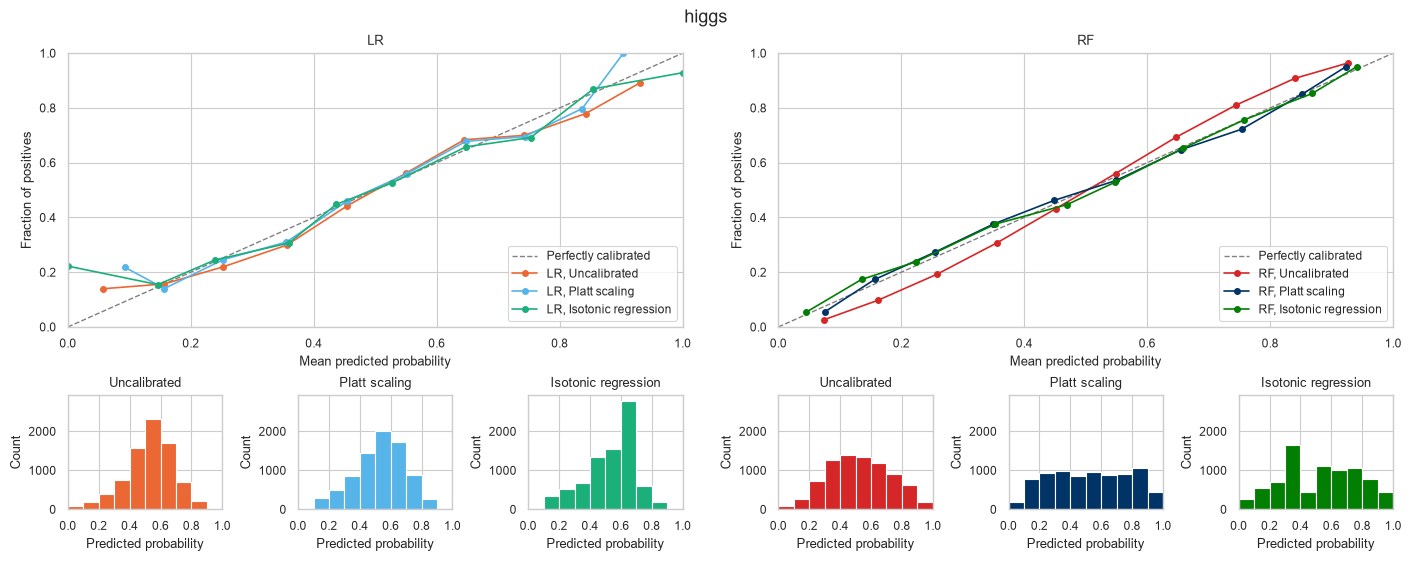

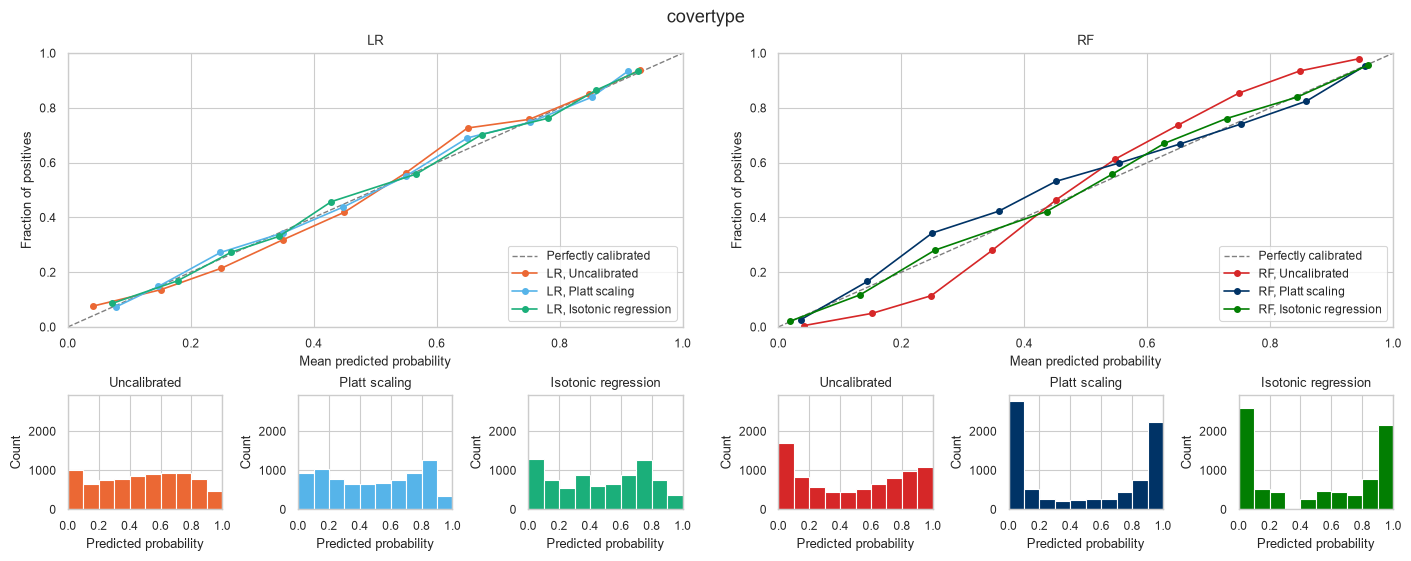

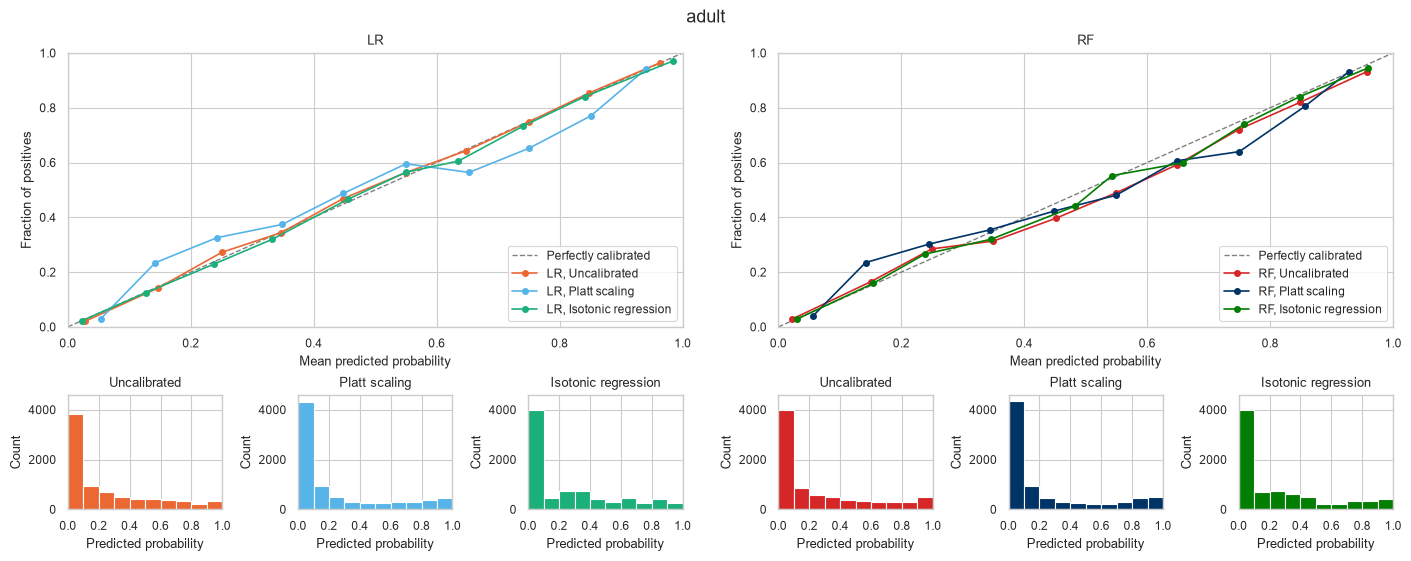

In [9]:
LABELS = {"uncalibrated": "Uncalibrated", "platt": "Platt scaling", "isotonic": "Isotonic regression"}
TO_SCORE = {"LR": lambda p: np.log(p / (1 - p)), 
            "RF": lambda p: p, 
}
MODEL_STYLES = {
    "LR": {"marker": "o", "linestyle": "-"},
    "RF": {"marker": "o", "linestyle": "-"},
}


MODEL_COLORS = {
    ("LR", "platt"): "#56b4e9",
    ("LR", "uncalibrated"):        "#eb6834",
    ("LR", "isotonic"):     "#1baf7a",
    ("RF", "platt"): "#003366",
    ("RF", "uncalibrated"):        "#d62728",
    ("RF", "isotonic"):     "#027E02",
}


def reliability_figure_side_by_side(name):
    y_test = data[name]["test"][1]
    fig = plt.figure(figsize=(14, 5.5), layout="constrained")
    fig.suptitle(name, fontsize=13)

    subfigs = fig.subfigures(1, len(MODELS), wspace=0.03)

    shared_hist = None
    for i, model_name in enumerate(MODELS):
        subfig = subfigs[i]
        gs = subfig.add_gridspec(2, len(METHODS), height_ratios=[2.4, 1])

        ax = subfig.add_subplot(gs[0, :])
        reliability_axes(ax, diagonal_label="Perfectly calibrated")
        ax.set_aspect("auto")
        ax.set_box_aspect(None)
        ax.set_title(model_name)
        

        for j, method in enumerate(METHODS):
            p = probs[name, model_name, method]["test"]
            label = f"{model_name}, {LABELS[method]}"
            color = MODEL_COLORS[model_name, method]

            reliability_curve(ax, y_test, p, color=color, markersize=4,
                              label=label, **MODEL_STYLES[model_name])

            ax_hist = subfig.add_subplot(gs[1, j], sharey=shared_hist)
            prediction_histogram(ax_hist, p, color)
            ax_hist.set_title(LABELS[method])
            if shared_hist is None:
                shared_hist = ax_hist

        ax.legend(loc="lower right")

    return fig


for name in DATASETS:
    fig = reliability_figure_side_by_side(name)
    fig.savefig(FIG_DIR / f"reliability_{name}_side_by_side.pdf", bbox_inches="tight")
    plt.show()

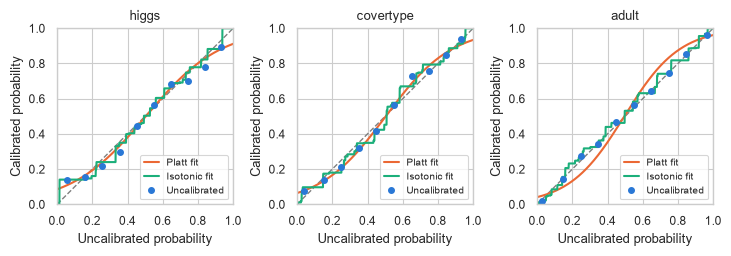

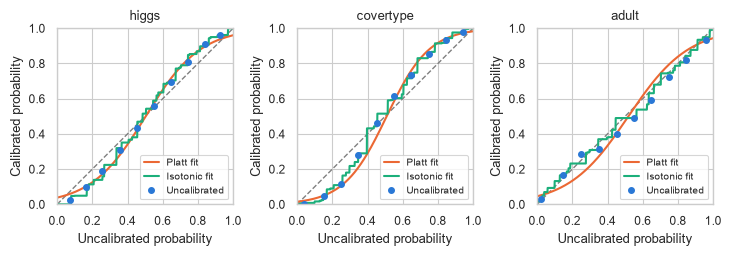

In [10]:
FIT_LABELS = {"platt": "Platt fit", "isotonic": "Isotonic fit"}   
COLORS = {"uncalibrated": "#2a78d6", "platt": "#eb6834", "isotonic": "#1baf7a"}




def calibration_maps_figure(model_name):
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(7.2, 2.8), layout="constrained")
    grid = np.linspace(0, 1, 2001)      
    for ax, name in zip(axes, DATASETS):
        reliability_axes(ax, xlabel="Uncalibrated probability", ylabel="Calibrated probability")
        for method in CALIBRATORS:
            ax.plot(grid, calibrators[name, model_name, method].predict_proba(grid),
                    color=COLORS[method], linewidth=1.5, label=FIT_LABELS[method])
        reliability_curve(ax, data[name]["test"][1], probs[name, model_name, "uncalibrated"]["test"],
                          color=COLORS["uncalibrated"], marker="o", linestyle="none", markersize=4,
                          label=LABELS["uncalibrated"])
        ax.set_title(name)
        ax.legend(loc="lower right", fontsize=7, handlelength=1.5)
    return fig


for model_name in MODELS:
    fig = calibration_maps_figure(model_name)
    fig.savefig(FIG_DIR / f"calibration_maps_{model_name}.pdf", bbox_inches="tight")
    plt.show()

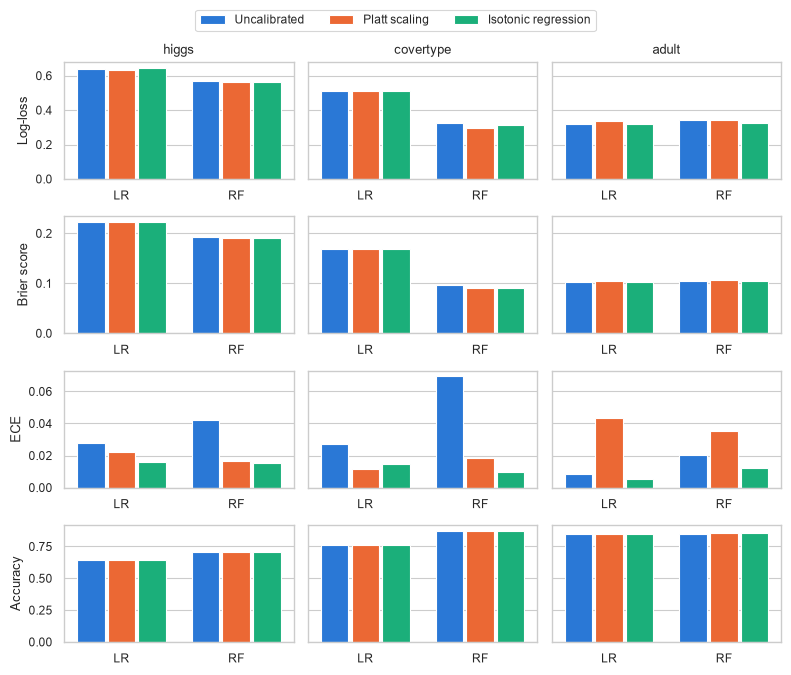

In [11]:
METRIC_LABELS = {"log_loss": "Log-loss", "brier": "Brier score", "ece": "ECE", "accuracy": "Accuracy"}

fig, axes = plt.subplots(len(METRIC_LABELS), len(DATASETS), figsize=(8, 6.5), sharey="row")
for i, (metric, metric_label) in enumerate(METRIC_LABELS.items()):
    for j, name in enumerate(DATASETS):
        ax = axes[i, j]
        rows = test_metrics[test_metrics["dataset"] == name]
        sns.barplot(data=rows[rows["model"] != "constant"], x="model", y=metric, hue="method",
                    hue_order=METHODS, palette=COLORS, saturation=1, gap=0.1, ax=ax)
        ax.set(title=name if i == 0 else "", xlabel="", ylabel=metric_label if j == 0 else "")
        handles, labels = ax.get_legend_handles_labels()
        ax.get_legend().remove()
fig.legend(handles, [LABELS.get(l, l) for l in labels], loc="upper center", ncol=4,
           bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
fig.savefig(FIG_DIR / "test_metrics.pdf", bbox_inches="tight")

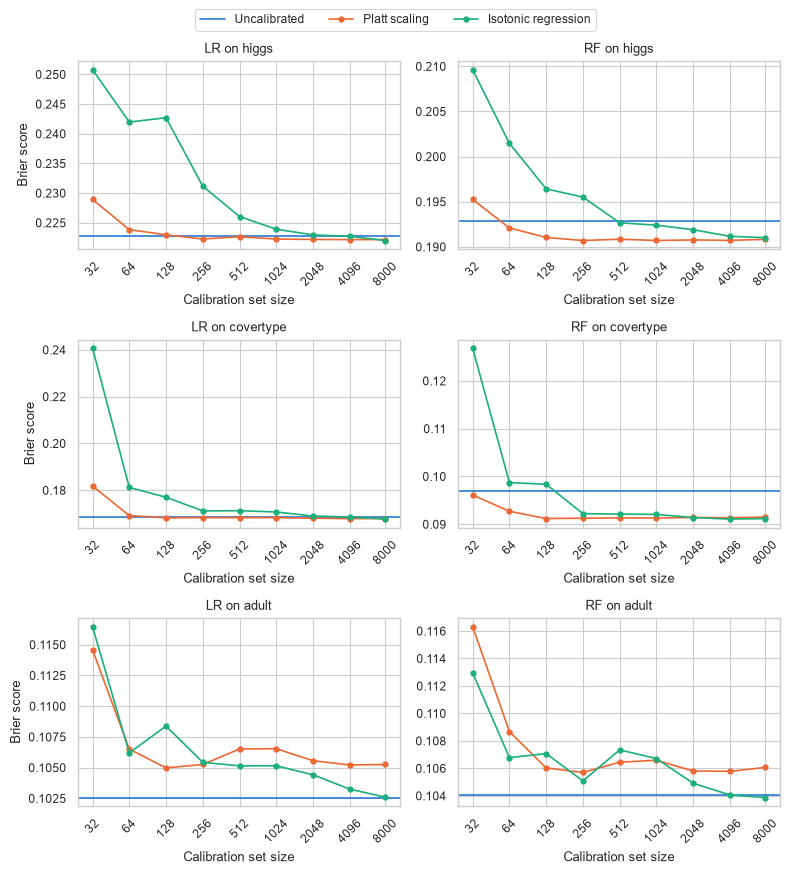

In [15]:
CAL_SIZES = [2 ** k for k in range(5, 13)]   


def stratified_order(y, random_state=RANDOM_STATE):
    rng = np.random.default_rng(random_state)
    rank = np.empty(len(y))
    for c in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == c))
        rank[idx] = (np.arange(len(idx)) + 0.5) / len(idx)
    return np.argsort(rank, kind="stable")


rows = []
for name, model_name in models:
    y_cal, y_test = data[name]["cal"][1], data[name]["test"][1]
    p_cal, p_test = outputs[name, model_name, "cal"], outputs[name, model_name, "test"]
    order = stratified_order(y_cal)
    for n in CAL_SIZES + [len(y_cal)]:
        idx = order[:n]
        info = {"dataset": name, "model": model_name, "size": n, "positives": int(y_cal[idx].sum())}
        rows.append({**info, "method": "uncalibrated", **evaluate(y_test, p_test)})
        for method, Calibrator in CALIBRATORS.items():
            p = Calibrator().fit(p_cal[idx], y_cal[idx]).predict_proba(p_test)
            rows.append({**info, "method": method, **evaluate(y_test, p)})

cal_size = pd.DataFrame(rows)
cal_size.to_csv(RESULTS_DIR / "calibration_size.csv", index=False)



fig, axes = plt.subplots(len(DATASETS), len(MODELS), figsize=(8, 8.5))
for i, name in enumerate(DATASETS):
    for j, model_name in enumerate(MODELS):
        g = cal_size[(cal_size["dataset"] == name) & (cal_size["model"] == model_name)]
        sizes = g.loc[g["method"] == "platt", "size"].to_numpy()
        series = [(g.loc[g["method"] == m, "brier"].to_numpy(), COLORS[m], LABELS[m])
                  for m in CALIBRATORS]
        uncal = g.loc[g["method"] == "uncalibrated", "brier"].iloc[0]
        calibration_size_curve(axes[i, j], sizes, series, uncal, COLORS["uncalibrated"])
        axes[i, j].set(title=f"{model_name} on {name}", xlabel="Calibration set size",
                       ylabel="Brier score" if j == 0 else "")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03))
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_size.pdf", bbox_inches="tight")